# 0. Table of contents
 

Lager oversikt her over hele filen (importering av biblioteker, datacleaning og modeller osv)

# 1. Importing Necessary Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Sets a consistent visual style for all exploratory figures.
sns.set_theme(style="whitegrid", context="notebook")

# Configures numerical display settings.
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)

RANDOM_STATE = 42

# 2. Data Understanding 


This section examines the structure, content, and quality of the Fish Weight Estimation dataset before developing the three models: Linear Regression, Support Vector Regression (SVR) and Random Forest Regression.

The dataset contains observations of seven fish species, including fish weight and five body measurements. The purpose of this exploratory analysis is to identify relevant patterns, find potential data quality issues, and establish a transparent basis for subsequent preprocessing and model selection.

**Data source:** `FishWeightEstimation.csv`, provided as part of the IND310 course project.

**Target variable:** `Weight` (grams).

**Numerical predictors:** `LengthVer`, `LengthDia`, `LengthCro`, `Height`, and `Width` (centimeters).

**Categorical variable:** `Species`.


## 2.1 Dataset Overview

In [2]:
# Loading the original dataset from the notebook's working directory.
DATA_PATH = Path("FishWeightEstimation.csv")

df = pd.read_csv(DATA_PATH)

# Removes accidental whitespace from column names.
df.columns = df.columns.str.strip()

# Renames measurment names for better understanding
df = df.rename(columns={
    "Length1": "LengthVer",
    "Length2": "LengthDia",
    "Length3": "LengthCro"
})

# Confirm that the expected variables are available.
expected_columns = [
    "Species", "Weight", "LengthVer", "LengthDia",
    "LengthCro", "Height", "Width"
]

assert set(expected_columns).issubset(df.columns), (
    "The dataset does not contain all expected columns."
)

print(f"Dataset dimensions: {df.shape[0]} rows × {df.shape[1]} columns")
display(df.head())


Dataset dimensions: 159 rows × 7 columns


,Species,Weight,LengthVer,LengthDia,LengthCro,Height,Width
0,Bream,242.00,23.20,25.40,30.00,11.52,4.02
1,Bream,290.00,24.00,26.30,31.20,12.48,4.31
2,Bream,340.00,23.90,26.50,31.10,12.38,4.70
3,Bream,363.00,26.30,29.00,33.50,12.73,4.46
4,Bream,430.00,26.50,29.00,34.00,12.44,5.13


In [3]:
# Inspect variable types and the number of non-null observations.
df.info()

# Present the variable types in a compact table.
variable_summary = pd.DataFrame({
    "Variable": df.columns,
    "Data type": df.dtypes.astype(str).values,
    "Non-null observations": df.notna().sum().values,
    "Unique values": df.nunique().values
})

display(variable_summary)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 159 entries, 0 to 158
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Species    159 non-null    object 
 1   Weight     159 non-null    float64
 2   LengthVer  159 non-null    float64
 3   LengthDia  159 non-null    float64
 4   LengthCro  159 non-null    float64
 5   Height     159 non-null    float64
 6   Width      159 non-null    float64
dtypes: float64(6), object(1)
memory usage: 8.8+ KB


,Variable,Data type,Non-null observations,Unique values
0,Species,object,159,7
1,Weight,float64,159,101
2,LengthVer,float64,159,116
3,LengthDia,float64,159,93
4,LengthCro,float64,159,124
5,Height,float64,159,154
6,Width,float64,159,152



### Initial observations

The dataset contains 159 observations and seven variables. Six variables are numerical, while `Species` is categorical.

The dataset is relatively small for machine learning, particularly because the observations represent several different fish species. This makes careful validation important and limits the reliability of species-specific models.

The original dataset will remain unchanged during exploratory analysis.


## 2.2 Data Quality Assesment

Before developing predictive models, the dataset must be assessed for missing values, duplicate records, and physically implausible measurements.

Identifying data quality issues is essential because incorrect observations may introduce bias, distort model parameters, and reduce predictive reliability.

At this stage, suspicious observations are flagged for investigation rather than automatically removed.

In [4]:

# Check for missing values in each variable.
missing_values = pd.DataFrame({
    "Missing values": df.isna().sum(),
    "Missing (%)": df.isna().mean() * 100
})

display(missing_values)

# Check for fully duplicated observations.
duplicate_count = df.duplicated().sum()

print(f"Number of duplicate rows: {duplicate_count}")
print(f"Total missing values: {df.isna().sum().sum()}")


,Missing values,Missing (%)
Species,0,0.00
Weight,0,0.00
LengthVer,0,0.00
LengthDia,0,0.00
LengthCro,0,0.00
Height,0,0.00
Width,0,0.00


Number of duplicate rows: 0
Total missing values: 0


In [5]:

# Define variables that should contain strictly positive measurements.
measurement_columns = [
    "Weight", "LengthVer", "LengthDia",
    "LengthCro", "Height", "Width"
]

# Identify observations containing zero or negative measurements.
invalid_mask = (df[measurement_columns] <= 0).any(axis=1)

invalid_observations = df.loc[invalid_mask]

print(f"Number of observations with invalid measurements: {invalid_mask.sum()}")
display(invalid_observations)


Number of observations with invalid measurements: 1


,Species,Weight,LengthVer,LengthDia,LengthCro,Height,Width
40,Roach,0.00,19.00,20.50,22.80,6.48,3.35


The initial assessment identified no missing values or fully duplicated observations.

However, one observation (index 40) has a recorded weight of 0 grams despite having positive body measurements. This is physically implausible and indicates a likely data recording or measurement issue.

**Preprocessing decision:** The observation will be excluded during data preparation because the recorded target value is not valid for the intended prediction task.

In [6]:
df = df[df["Weight"] > 0].copy()

## 2.3 Descriptive Statistics

Descriptive statistics are used to examine the central tendency, variability, and range of the numerical variables.

Particular attention is given to fish weight, as large differences in body size may affect both model performance and the interpretation of prediction errors.


In [7]:

# Summarizing the distribution of all numerical measurements.
summary_statistics = df[measurement_columns].describe().T

# Adding the median explicitly for easier comparison with the mean.
summary_statistics["median"] = df[measurement_columns].median()

display(summary_statistics.round(2))


,count,mean,std,min,25%,50%,75%,max,median
Weight,158.00,400.85,357.70,5.90,121.25,281.50,650.00,1650.00,281.50
LengthVer,158.00,26.29,10.01,7.50,19.15,25.30,32.70,59.00,25.30
LengthDia,158.00,28.47,10.73,8.40,21.00,27.40,35.75,63.40,27.40
LengthCro,158.00,31.28,11.63,8.80,23.20,29.70,39.68,68.00,29.70
Height,158.00,8.99,4.30,1.73,5.94,7.79,12.37,18.96,7.79
Width,158.00,4.42,1.69,1.05,3.40,4.28,5.59,8.14,4.28


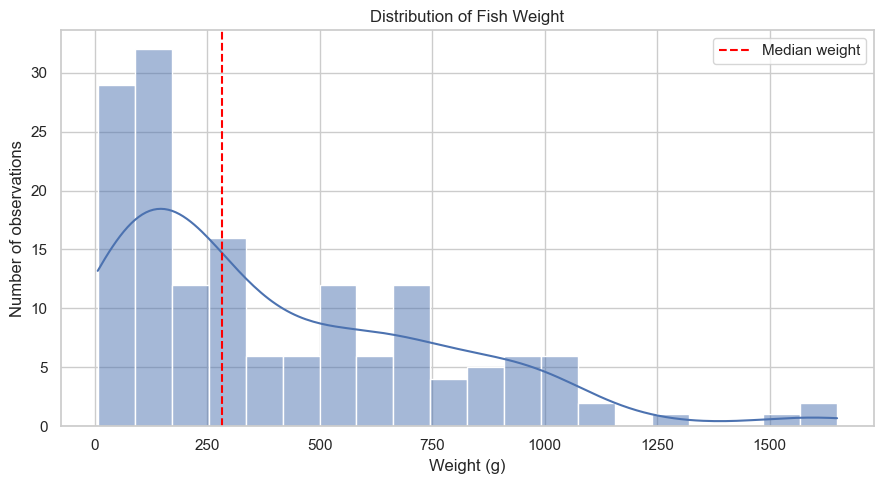

In [8]:

# Visualizing the distribution of the target variable.
fig, ax = plt.subplots(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Weight",
    bins=20,
    kde=True,
    ax=ax
)

ax.axvline(
    df["Weight"].median(),
    color="red",
    linestyle="--",
    label="Median weight"
)

ax.set(
    title="Distribution of Fish Weight",
    xlabel="Weight (g)",
    ylabel="Number of observations"
)

ax.legend()
plt.tight_layout()
plt.show()



### Descriptive findings

Fish weight varies substantially across the dataset, ranging from around 6 grams to 1,650 grams in the data (after removing the zero value).

The mean weight is approximately 400 grams, while the median is 281.5 grams. This difference indicates a right-skewed weight distribution, where relatively large fish increase the mean.

The substantial variation in weight suggests that model performance should be assessed using error measures expressed in grams, in addition to R².


## 2.4 Species Distribution

The dataset includes several fish species with potentially different body shapes and weight-to-length relationships.

Examining the distribution of species is important for understanding dataset representativeness and the limitations of developing a single predictive model across multiple species.

,Count,Percentage (%)
Species,,
Perch,56,35.44
Bream,35,22.15
Roach,19,12.03
Pike,17,10.76
Smelt,14,8.86
Parkki,11,6.96
Whitefish,6,3.80


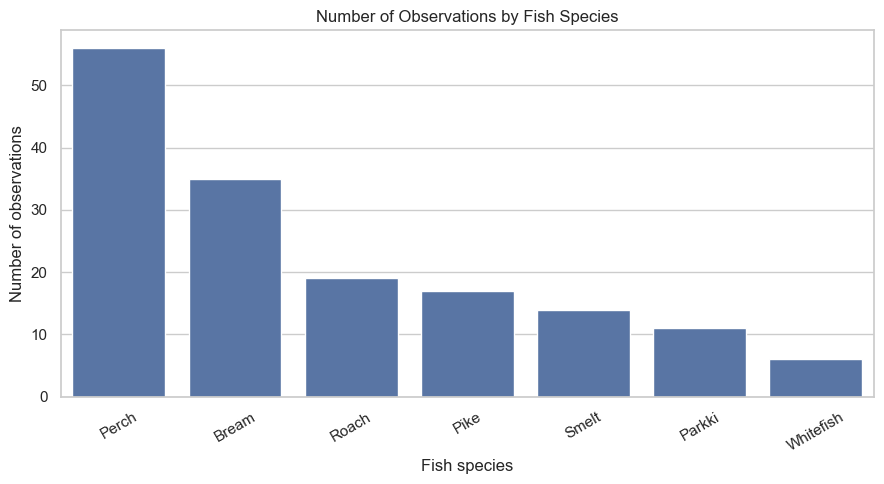

In [9]:

# Calculate the number and proportion of observations per species.
species_distribution = df["Species"].value_counts()

species_summary = pd.DataFrame({
    "Count": species_distribution,
    "Percentage (%)": species_distribution / len(df) * 100
})

display(species_summary.round(2))

# Visualize the class imbalance between fish species.
fig, ax = plt.subplots(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Species",
    order=species_distribution.index,
    ax=ax
)

ax.set(
    title="Number of Observations by Fish Species",
    xlabel="Fish species",
    ylabel="Number of observations"
)

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


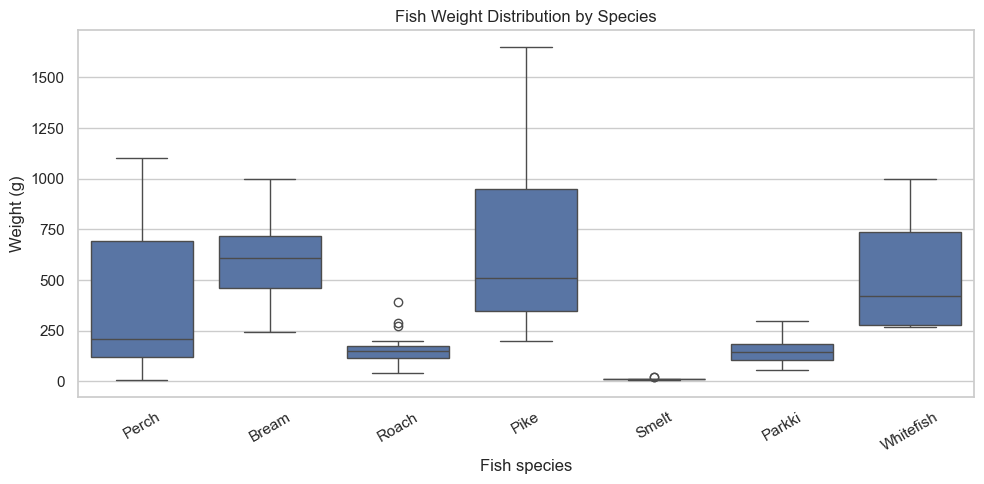

In [10]:

# Compare the weight distributions across fish species.
fig, ax = plt.subplots(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="Species",
    y="Weight",
    order=species_distribution.index,
    ax=ax
)

ax.set(
    title="Fish Weight Distribution by Species",
    xlabel="Fish species",
    ylabel="Weight (g)"
)

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()



The dataset contains seven fish species with an uneven distribution of observations. Perch is the most frequently represented species (56 observations), while Whitefish has only six observations.

This imbalance introduces an important modeling limitation. Species with more observations may have greater influence on a pooled model, while the predictive performance for less represented species may be difficult to assess reliably.

Separate models for every species are therefore not considered appropriate for the primary analysis, given the limited sample sizes.

Instead, the main analysis will evaluate pooled models using body measurements, followed by an investigation of prediction errors across species.

## 2.5 Exploratory Data Analysis


Exploratory visualizations are used to investigate relationships between fish weight and the available body measurements.

These relationships may be nonlinear and may differ across fish species. Identifying such patterns provides useful context for comparing linear regression, support vector regression, and random forest regression.

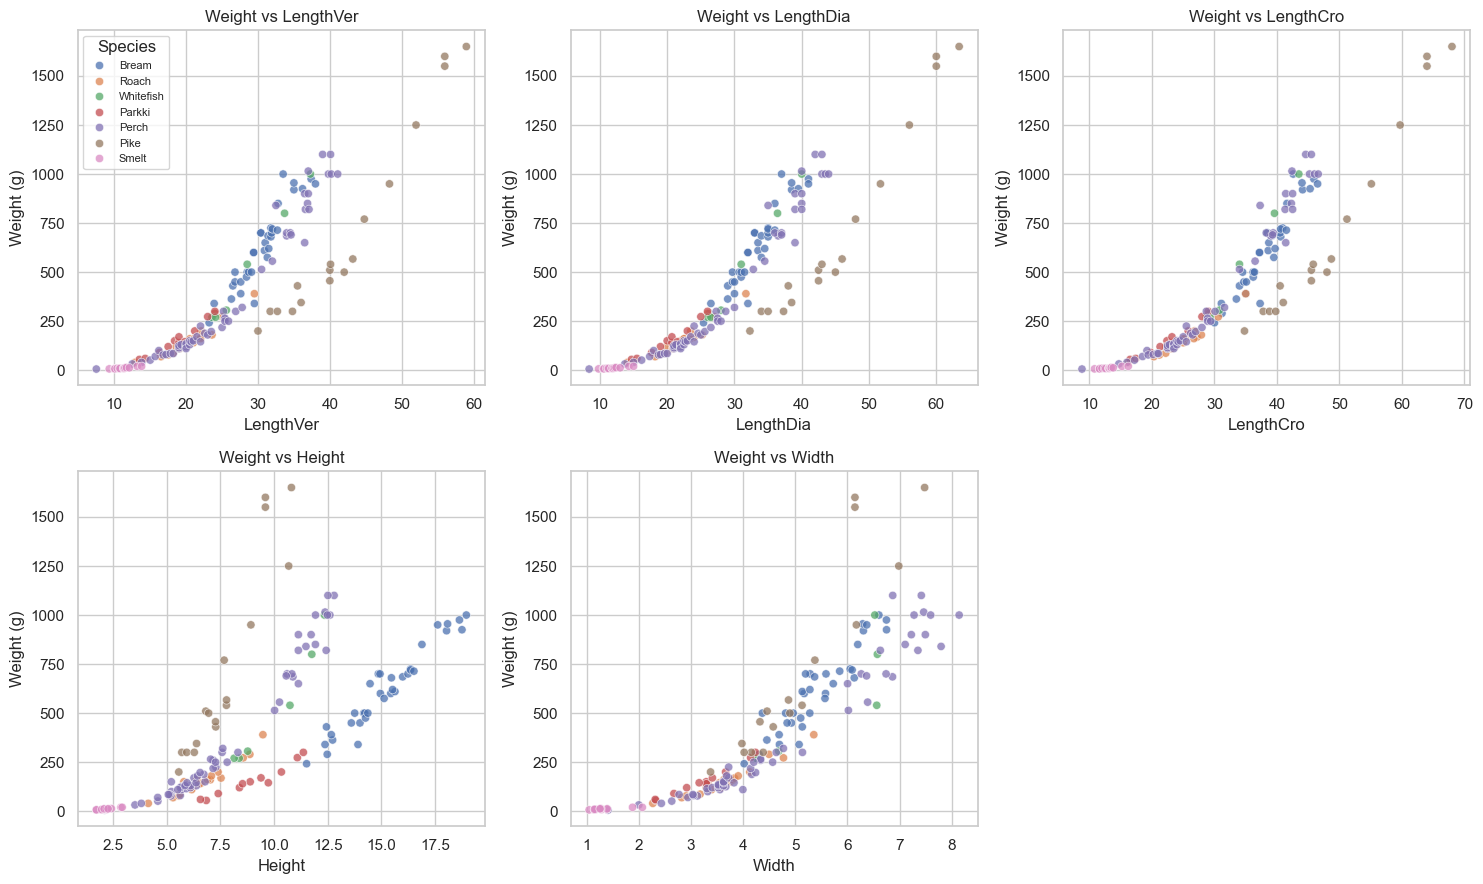

In [11]:

# Examines the relationship between each body measurement and fish weight.
predictor_columns = [
    "LengthVer", "LengthDia", "LengthCro",
    "Height", "Width"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, feature in enumerate(predictor_columns):
    sns.scatterplot(
        data=df,
        x=feature,
        y="Weight",
        hue="Species",
        legend=(i == 0),
        alpha=0.75,
        ax=axes[i]
    )

    axes[i].set_title(f"Weight vs {feature}")
    axes[i].set_ylabel("Weight (g)")

    if i == 0:
        axes[i].legend(
            title="Species",
            fontsize=8,
            loc="upper left"
        )

# Remove the unused sixth subplot.
fig.delaxes(axes[-1])

plt.tight_layout()
plt.show()


The scatterplots suggest a positive, nonlinear relationship between fish length and weight. This pattern can be explained by the three-dimensional nature of fish growth. As fish increase in length, their height and width generally increase as well, resulting in a greater increase in body volume and, consequently, weight.

Assuming approximately constant body proportions and density, fish weight is expected to increase roughly with the cube of length. However, differences in body shape and growth patterns between species may cause deviations from this relationship.

These observations suggest that the relationship between body measurements and weight may not be adequately represented by a purely linear model. This provides a theoretical motivation for comparing Linear Regression with nonlinear approaches such as Support Vector Regression and Random Forest Regression.

## 2.6 Correlation Analysis

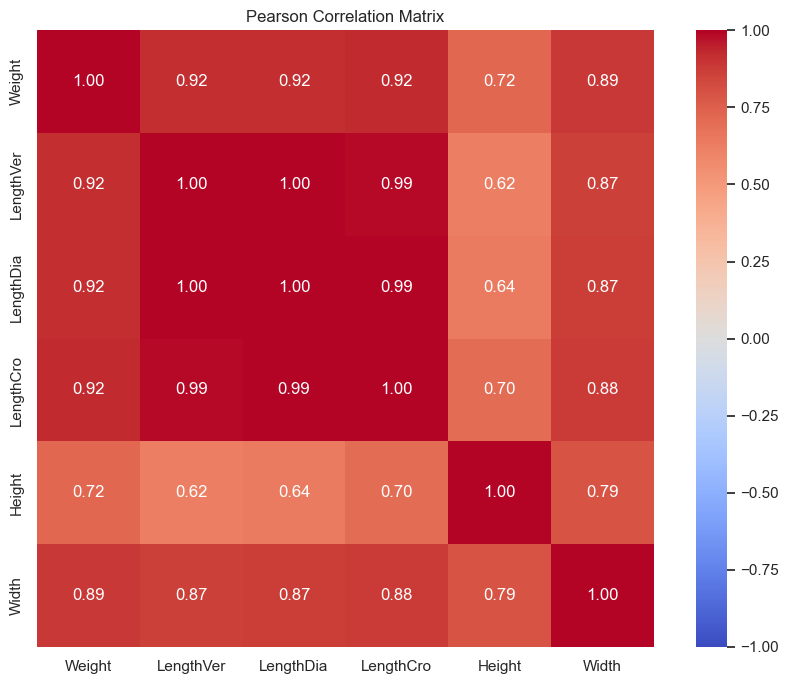

In [12]:

# Calculating Pearson correlations between numerical variables.
correlation_matrix = df[measurement_columns].corr()

fig, ax = plt.subplots(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True,
    ax=ax
)

ax.set_title("Pearson Correlation Matrix")
plt.tight_layout()
plt.show()


In [13]:

# Rank numerical predictors by their linear association with weight.
weight_correlations = (
    correlation_matrix["Weight"]
    .drop("Weight")
    .sort_values(ascending=False)
)

display(weight_correlations.to_frame("Correlation with Weight"))


,Correlation with Weight
LengthCro,0.92
LengthDia,0.92
LengthVer,0.92
Width,0.89
Height,0.72


### Correlation Analysis – Findings

The Pearson correlation matrix reveals strong positive relationships between fish weight and all five body measurements. The three length measurements (`LengthVer`, `LengthDia`, and `LengthCro`) exhibit the strongest correlations with weight (r ≈ 0.92), followed by Width (r = 0.89) and Height (r = 0.72).

A particularly important finding is the extremely high correlation between the three length measurements (r ≈ 0.99–1.00), indicating substantial overlap in the information they provide. Including these variables simultaneously in a linear regression model may therefore introduce multicollinearity, potentially reducing the stability and interpretability of individual regression coefficients.

Height exhibits weaker correlations with the length measurements (r = 0.62–0.70), suggesting that it may capture additional information about fish body shape. However, whether this information improves predictive performance must be established through model evaluation.

Finally, Pearson correlation measures linear relationships and does not fully capture the nonlinear patterns observed in the scatterplots. These findings support the comparison of different feature combinations and regression algorithms to determine which approach provides the most reliable predictions on unseen data.

### Implications for Feature Selection

The correlation analysis provides an important basis for evaluating the three feature groups specified in the assignment.

The first feature group (`LengthVer` and `LengthDia`) contains two almost perfectly correlated measurements, suggesting substantial redundancy. In contrast, the second feature group (`LengthCro`, `Height`, and `Width`) combines measurements of different body dimensions, potentially capturing more information about fish shape and volume.

Although all five numerical predictors are positively correlated with weight, their individual correlations do not necessarily reflect their contribution to a multivariable prediction model. The third feature group will therefore be used to investigate whether including all measurements improves predictive performance or introduces unnecessary complexity.

These hypotheses will be evaluated by comparing Linear Regression, Support Vector Regression, and Random Forest Regression across all three feature groups, using consistent validation procedures and prediction error metrics.

## 2.7 Outlier Investigation

Potential outliers are investigated to assess whether extreme observations represent measurement errors or natural variation in fish size.

The interquartile range (IQR) method is applied to identify observations outside the interval defined by Q1 − 1.5 × IQR and Q3 + 1.5 × IQR.

Since the dataset contains seven fish species with different body characteristics, observations classified as statistical outliers may still represent valid biological measurements. Therefore, the IQR method is used to identify observations for further investigation rather than as an automatic exclusion criterion.


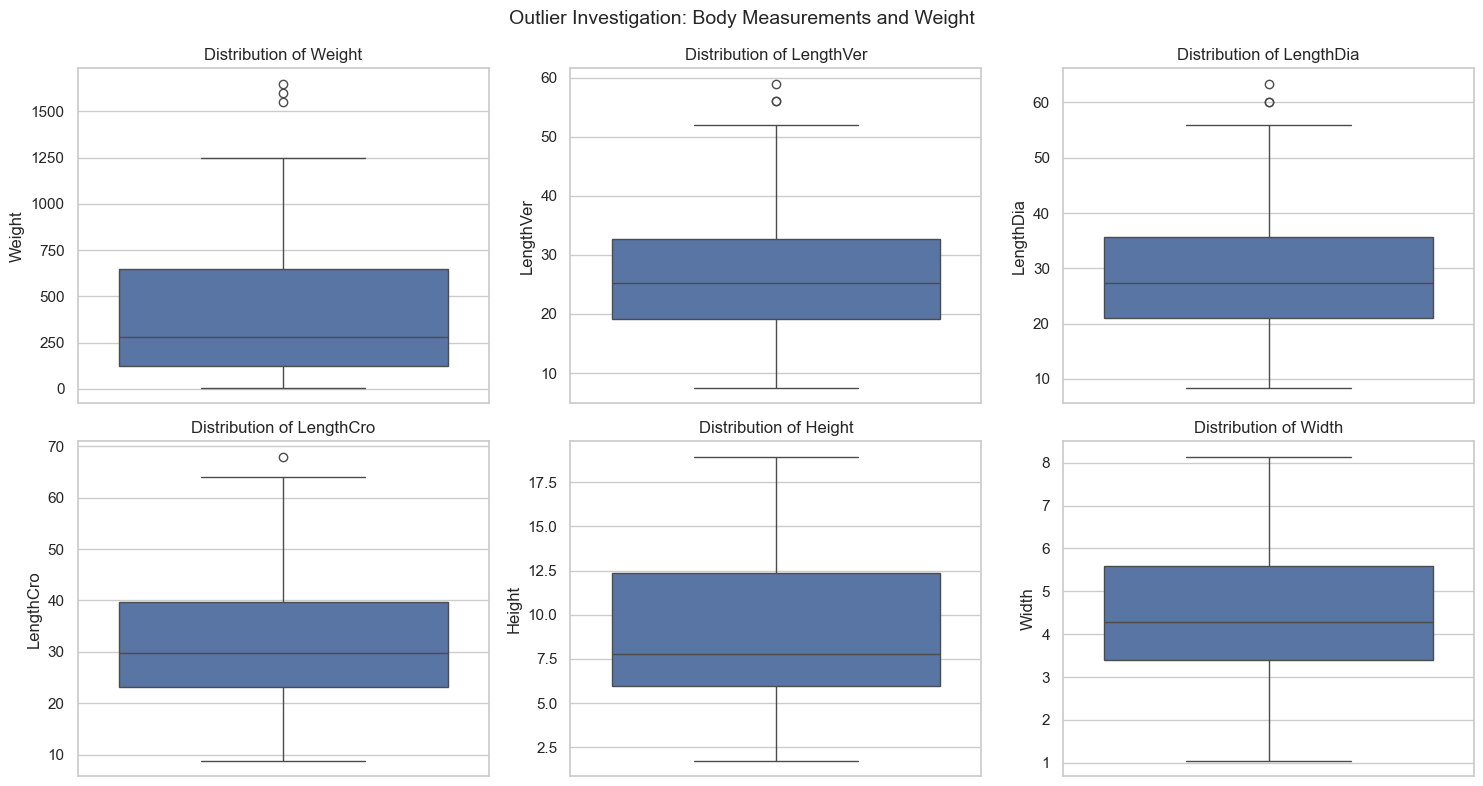

In [14]:

# Visualizing potential outliers across all numerical measurements.
# Boxplots display the median, interquartile range, and extreme values.

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, column in zip(axes.flat, measurement_columns):
    sns.boxplot(
        y=df[column],
        ax=ax
    )

    ax.set_title(f"Distribution of {column}")
    ax.set_ylabel(column)

plt.suptitle("Outlier Investigation: Body Measurements and Weight", fontsize=14)
plt.tight_layout()
plt.show()


### Boxplot Analysis – Findings

The boxplots reveal several potential outliers in fish weight and the three length measurements, while no apparent outliers are observed for Height or Width.

The most extreme weight observations are substantially larger than the majority of the dataset. Given the strong positive relationships between length and weight identified earlier, these values may reflect naturally larger fish rather than measurement errors.

However, the presence of multiple fish species makes it important to distinguish between statistical outliers and biologically implausible measurements. Therefore, the flagged observations will be examined using the IQR method and compared with observations from the same species before making any exclusion decisions.

In [15]:

# Identify potential outliers using the interquartile range (IQR).
# Observations are flagged for further investigation, not removed.

outlier_flags = pd.DataFrame(index=df.index)
outlier_summary = []

for column in measurement_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_flags[column] = (
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    )

    outlier_summary.append({
        "Variable": column,
        "Lower bound": lower_bound,
        "Upper bound": upper_bound,
        "Flagged observations": outlier_flags[column].sum()
    })

# Display IQR thresholds and the number of flagged observations.
display(pd.DataFrame(outlier_summary).round(2))

# Identify the individual fish flagged in at least one measurement.
flagged_observations = df.loc[
    outlier_flags.any(axis=1)
].copy()

flagged_observations["Flagged variables"] = outlier_flags.loc[
    flagged_observations.index
].apply(
    lambda row: ", ".join(row.index[row]),
    axis=1
)

display(flagged_observations)


,Variable,Lower bound,Upper bound,Flagged observations
0,Weight,-671.88,1443.12,3
1,LengthVer,-1.18,53.03,3
2,LengthDia,-1.12,57.88,3
3,LengthCro,-1.51,64.39,1
4,Height,-3.71,22.02,0
5,Width,0.12,8.87,0


,Species,Weight,LengthVer,LengthDia,LengthCro,Height,Width,Flagged variables
142,Pike,1600.00,56.00,60.00,64.00,9.60,6.14,"Weight, LengthVer, LengthDia"
143,Pike,1550.00,56.00,60.00,64.00,9.60,6.14,"Weight, LengthVer, LengthDia"
144,Pike,1650.00,59.00,63.40,68.00,10.81,7.48,"Weight, LengthVer, LengthDia, LengthCro"


In [16]:

# Identify observations flagged as potential outliers
# in at least one numerical variable.

flagged_observations = df.loc[
    outlier_flags.any(axis=1)
].copy()

# Identify the variables responsible for each outlier flag.
flagged_observations["Flagged variables"] = (
    outlier_flags.loc[flagged_observations.index]
    .apply(
        lambda row: ", ".join(row.index[row]),
        axis=1
    )
)

# Display flagged observations, including species
# and the original row indices.
print(f"Total number of flagged fish: {len(flagged_observations)}")

display(
    flagged_observations.sort_values(
        by="Weight",
        ascending=False
    )
)


Total number of flagged fish: 3


,Species,Weight,LengthVer,LengthDia,LengthCro,Height,Width,Flagged variables
144,Pike,1650.00,59.00,63.40,68.00,10.81,7.48,"Weight, LengthVer, LengthDia, LengthCro"
142,Pike,1600.00,56.00,60.00,64.00,9.60,6.14,"Weight, LengthVer, LengthDia"
143,Pike,1550.00,56.00,60.00,64.00,9.60,6.14,"Weight, LengthVer, LengthDia"


### Outlier Investigation – Findings and Decision

The IQR analysis identified three unique observations (indices 142, 143, and 144) as potential outliers. All three belong to the Pike species and have weights ranging from 1,550 to 1,650 grams.

These observations were flagged primarily due to their high weights and large length measurements. Importantly, the extreme weight values are accompanied by correspondingly large body dimensions, suggesting that they may represent natural biological variation rather than measurement errors.

An additional observation is that indices 142 and 143 have identical recorded body measurements but different weights. This indicates that body measurements alone may not fully explain the variation in fish weight.

**Decision:** The three observations will be retained in the primary analysis, as there is insufficient evidence to classify them as erroneous. Removing them solely because they exceed the IQR thresholds could reduce the representation of larger fish and limit the range of measurements available for model training.

The influence of these observations on predictive performance may be examined through a sensitivity analysis during model evaluation.

## 2.8 Data Understanding Summary

The exploratory analysis identified several important characteristics of the Fish Weight Estimation dataset.

The original dataset contained 159 observations across seven fish species. One observation with a recorded weight of zero was excluded due to its physically implausible target value, leaving 158 observations for further analysis.

The correlation analysis revealed strong positive relationships between fish weight and all five body measurements. The three length measurements were also highly correlated with one another, indicating potential multicollinearity. Furthermore, the exploratory visualizations suggested a nonlinear relationship between fish length and weight.

The species distribution was uneven, with relatively few observations for certain species. This limits the reliability of species-specific modeling and highlights the importance of evaluating prediction errors across different fish species.

Finally, the IQR analysis identified three unusually large Pike observations. These were retained because their measurements appeared plausible, and there was insufficient evidence to classify them as erroneous.

Together, these findings provide a foundation for comparing the three feature combinations and three regression algorithms specified in the assignment.

# 3. Preparing Machine Learning Models

## 3.1 Dataset Preparation

The observation with an invalid weight of zero grams was removed during the initial data quality assessment. The three statistically extreme Pike observations were retained, as their measurements appeared biologically plausible and there was insufficient evidence to classify them as erroneous.

The resulting dataset contains 158 observations and is used consistently throughout model development.

In [17]:

# Create a separate dataset for machine learning.
# The invalid zero-weight observation has already been removed.

df_model = df.copy()

# Verify that the dataset is ready for modeling.
print(f"Number of observations: {len(df_model)}")
print(f"Number of fish species: {df_model['Species'].nunique()}")

assert len(df_model) == 158, "Expected 158 observations after cleaning."
assert (df_model["Weight"] > 0).all(), "Invalid weight values remain."

display(df_model.head())


Number of observations: 158
Number of fish species: 7


,Species,Weight,LengthVer,LengthDia,LengthCro,Height,Width
0,Bream,242.00,23.20,25.40,30.00,11.52,4.02
1,Bream,290.00,24.00,26.30,31.20,12.48,4.31
2,Bream,340.00,23.90,26.50,31.10,12.38,4.70
3,Bream,363.00,26.30,29.00,33.50,12.73,4.46
4,Bream,430.00,26.50,29.00,34.00,12.44,5.13


## 3.2 Feature Group Definition

Three feature groups are defined according to the assignment requirements.

- **Feature Group 1 – Length Measurements:** LengthVer and LengthDia.
- **Feature Group 2 – Body Dimensions:** LengthCro, Height, and Width.
- **Feature Group 3 – All Numerical Features:** LengthVer, LengthDia, LengthCro, Height, and Width.

The feature groups allow us to investigate whether highly correlated length measurements provide sufficient predictive information, whether combining different body dimensions improves predictions, and whether including all numerical measurements provides an additional benefit.

The target variable is Weight, measured in grams.

Species is retained for subsequent error analysis but is not included as a predictor in the primary nine-model comparison.


In [18]:

# Define the three feature combinations specified in the assignment.

feature_groups = {
    "Group 1 - Length": [
        "LengthVer",
        "LengthDia"
    ],
    "Group 2 - Body dimensions": [
        "LengthCro",
        "Height",
        "Width"
    ],
    "Group 3 - All features": [
        "LengthVer",
        "LengthDia",
        "LengthCro",
        "Height",
        "Width"
    ]
}

# Define the target variable.
target_column = "Weight"

# Display the feature groups in a structured format.
feature_summary = pd.DataFrame([
    {
        "Feature group": group_name,
        "Number of features": len(features),
        "Features": ", ".join(features)
    }
    for group_name, features in feature_groups.items()
])

display(feature_summary)


,Feature group,Number of features,Features
0,Group 1 - Length,2,"LengthVer, LengthDia"
1,Group 2 - Body dimensions,3,"LengthCro, Height, Width"
2,Group 3 - All features,5,"LengthVer, LengthDia, LengthCro, Height, Width"


## 3.3 Train-Test Split

The dataset is divided into training (80%) and testing (20%) subsets.

To maintain a similar distribution of fish species across the two subsets, stratified sampling is applied using the Species variable. This is particularly relevant because the dataset contains seven unevenly represented fish species.

A fixed random state ensures reproducibility. The same training and test observations will be used for all nine model combinations, allowing a consistent comparison of feature groups and regression algorithms.

The test set will remain untouched during model fitting and hyperparameter selection. Model development and cross-validation will be performed exclusively on the training data.

In [19]:

from sklearn.model_selection import train_test_split

# Split observation indices rather than individual feature matrices.
# This guarantees identical train-test observations across all models.

train_idx, test_idx = train_test_split(
    df_model.index,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=df_model["Species"]
)

# Separate the target variable for training and testing.
y_train = df_model.loc[train_idx, target_column]
y_test = df_model.loc[test_idx, target_column]

# Store the feature matrices for all three feature groups.
X_train_groups = {}
X_test_groups = {}

for group_name, features in feature_groups.items():
    X_train_groups[group_name] = df_model.loc[train_idx, features]
    X_test_groups[group_name] = df_model.loc[test_idx, features]

# Verify that the training and test sets do not overlap.
assert len(set(train_idx) & set(test_idx)) == 0

print(f"Training observations: {len(train_idx)}")
print(f"Testing observations: {len(test_idx)}")
print(f"Total observations: {len(df_model)}")


Training observations: 126
Testing observations: 32
Total observations: 158



## 3.4 Model Development

Three regression algorithms are selected to evaluate their ability to predict fish weight:

- **Linear Regression:** A baseline model that assumes an additive linear relationship between the predictors and fish weight.
- **Support Vector Regression (SVR):** A regression algorithm capable of modeling nonlinear relationships through kernel functions.
- **Random Forest Regression:** An ensemble learning algorithm that combines multiple decision trees to capture complex relationships.

Each algorithm will be evaluated using the three feature groups defined in Section 3.2, resulting in nine model combinations.

To prevent data leakage, feature scaling is incorporated into a preprocessing pipeline for SVR. Linear Regression and Random Forest Regression are evaluated without feature scaling.


In [20]:

from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Define the three regression algorithms.
# Pipelines keep preprocessing and model fitting together.

models = {
    "Linear Regression": Pipeline([
        ("model", LinearRegression())
    ]),

    "Support Vector Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVR(kernel="rbf"))
    ]),

    "Random Forest Regression": Pipeline([
        ("model", RandomForestRegressor(
            n_estimators=200,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ])
}

print(f"Number of algorithms: {len(models)}")
print(f"Number of feature groups: {len(feature_groups)}")
print(f"Total model combinations: {len(models) * len(feature_groups)}")


Number of algorithms: 3
Number of feature groups: 3
Total model combinations: 9


## 3.5 Cross Validation


### 3.5.1 Model Evaluation Metrics

To evaluate and compare the predictive performance of the regression models, three complementary metrics are used: Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the Coefficient of Determination (R²).

These metrics assess different aspects of prediction quality and provide a more comprehensive evaluation than relying on a single performance measure.

Let:

- $y_i$ = Actual fish weight for observation $i$ (g)
- $\hat{y}_i$ = Predicted fish weight for observation $i$ (g)
- $\bar{y}$ = Mean actual fish weight in the evaluated dataset (g)
- $n$ = Number of evaluated observations

#### 1. Mean Absolute Error (MAE)

Mean Absolute Error measures the average absolute difference between actual and predicted fish weights.

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i-\hat{y}_i|
$$

MAE expresses prediction error in the same unit as the target variable, which in this dataset is grams.

For example, an MAE of 40 g means that the model's predictions deviate from the actual fish weights by an average of 40 g in absolute terms.

**Interpretation:**
- Lower MAE indicates better predictive accuracy.
- MAE treats all absolute errors proportionally.
- MAE is relatively easy to interpret in practical applications.

#### 2. Root Mean Squared Error (RMSE)

Root Mean Squared Error measures the square root of the average squared prediction error.

$$
RMSE = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2}
$$

Because prediction errors are squared before averaging, RMSE assigns greater weight to large errors than MAE.

For example, a model that usually predicts accurately but occasionally makes substantial errors may have a relatively low MAE but a considerably higher RMSE.

**Interpretation:**
- Lower RMSE indicates better predictive accuracy.
- RMSE is particularly sensitive to large prediction errors.
- RMSE is expressed in grams, allowing direct interpretation in the context of fish weight estimation.

Comparing RMSE with MAE can provide useful information about whether a model occasionally produces unusually large errors.

#### 3. Coefficient of Determination (R²)

The coefficient of determination measures how well the model's predictions explain variation in fish weight relative to a baseline that always predicts the mean observed weight.

$$
R^2 = 1 -
\frac{\sum_{i=1}^{n}(y_i-\hat{y}_i)^2}
{\sum_{i=1}^{n}(y_i-\bar{y})^2}
$$

**Interpretation:**
- $R^2 = 1$: Perfect predictions.
- $R^2 = 0$: The model performs equally well as predicting the mean weight for every observation.
- $R^2 < 0$: The model performs worse than the mean-prediction baseline.

Higher R² values generally indicate better predictive performance.

However, R² does not express prediction error in grams and should not be interpreted as the percentage of individual predictions that are correct.

#### Why Use All Three Metrics?

The three metrics provide complementary information:

| Metric | Measures | Preferred value | Unit |
|---|---|---|---|
| MAE | Average absolute prediction error | Lower | Grams |
| RMSE | Prediction error with greater emphasis on large deviations | Lower | Grams |
| R² | Predictive performance relative to the mean-weight baseline | Higher | Dimensionless |

For this study, MAE is used as the primary metric for model comparison because it provides an intuitive measure of prediction error in grams.

RMSE is included to assess the influence of larger prediction errors, while R² provides information about overall predictive performance relative to a simple baseline.

During cross-validation, these metrics are calculated separately for each validation fold and then summarized across folds. The resulting mean scores are used to compare the regression algorithms and feature groups.

Final model performance will subsequently be assessed using the independent test dataset.


### 3.5.2 Code for evaluation

In [21]:

from sklearn.model_selection import KFold, cross_validate

# Use identical cross-validation folds for every model.
cv = KFold(
    n_splits=10,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Define evaluation metrics.
scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

cv_results = []

# Evaluate every algorithm with each feature group.
for group_name, X_train in X_train_groups.items():

    for model_name, model in models.items():

        scores = cross_validate(
            estimator=model,
            X=X_train,
            y=y_train,
            cv=cv,
            scoring=scoring,
            n_jobs=-1
        )

        cv_results.append({
            "Feature Group": group_name,
            "Algorithm": model_name,
            "MAE (g)": -scores["test_MAE"].mean(),
            "RMSE (g)": -scores["test_RMSE"].mean(),
            "R²": scores["test_R2"].mean(),
            "MAE Std (g)": scores["test_MAE"].std()
        })

# Convert results into a comparison table.
cv_results_df = pd.DataFrame(cv_results)

# Rank model combinations by mean cross-validation MAE.
cv_results_df = cv_results_df.sort_values(
    by="MAE (g)",
    ascending=True
).reset_index(drop=True)

display(cv_results_df.round(3))


,Feature Group,Algorithm,MAE (g),RMSE (g),R²,MAE Std (g)
0,Group 2 - Body dimensions,Random Forest Regression,40.02,63.65,0.95,27.89
1,Group 3 - All features,Random Forest Regression,40.35,64.37,0.95,28.66
2,Group 1 - Length,Random Forest Regression,86.24,145.08,0.70,27.07
3,Group 3 - All features,Linear Regression,94.46,121.43,0.81,22.70
4,Group 2 - Body dimensions,Linear Regression,97.76,124.17,0.79,20.14
5,Group 1 - Length,Linear Regression,117.71,144.24,0.65,19.18
6,Group 3 - All features,Support Vector Regression,244.39,314.86,-0.05,68.99
7,Group 2 - Body dimensions,Support Vector Regression,245.38,315.65,-0.06,69.00
8,Group 1 - Length,Support Vector Regression,246.22,316.12,-0.06,69.61


### Cross-Validation – Findings

The 10-fold cross-validation results reveal substantial differences in predictive performance across the nine model combinations.

Random Forest Regression achieved the lowest prediction errors, particularly when using Feature Group 2 (`LengthCro`, `Height`, and `Width`). This combination obtained a mean absolute error (MAE) of 40.02 grams, a root mean squared error (RMSE) of 63.65 grams, and a mean R² of approximately 0.95.

Interestingly, including all five body measurements (Feature Group 3) did not provide a meaningful improvement, with Random Forest achieving a similar MAE of 40.35 grams. This is consistent with the earlier correlation analysis, which revealed substantial redundancy between the three length measurements.

Feature Group 1, containing only `LengthVer` and `LengthDia`, produced substantially higher prediction errors. This suggests that combining length with height and width provides more useful information for estimating fish weight than relying on two highly correlated length measurements alone.

Random Forest also outperformed Linear Regression across all three feature groups. This is consistent with the nonlinear relationships observed during exploratory data analysis, although the results alone do not establish the underlying biological mechanism.

In contrast, Support Vector Regression performed poorly with the initial model configuration, producing MAE values of approximately 244–246 grams and negative mean R² values. However, these results should not be interpreted as evidence that SVR is inherently unsuitable for this task, as its performance is sensitive to hyperparameter selection.

Finally, the relatively large variation in MAE across cross-validation folds indicates uncertainty in model performance. In particular, the small difference between the two best Random Forest configurations is insufficient to establish a clear advantage for either feature group.

Further investigation of SVR hyperparameters and evaluation on the held-out test set are therefore necessary before selecting a final model.

## 3.6 Hyperparameter Selection

The baseline cross-validation results indicated that Support Vector Regression performed poorly using its default hyperparameters.

To investigate whether alternative settings improve its predictive performance, GridSearchCV is applied to optimize C, epsilon, and gamma for each of the three feature groups.

Hyperparameter optimization is performed exclusively on the training data. The test set is reserved for independent evaluation after model development.


In [22]:

from sklearn.base import clone
from sklearn.model_selection import GridSearchCV

# Define candidate hyperparameters for Support Vector Regression.
# C controls the penalty for prediction errors.
# Epsilon defines the error tolerance.
# Gamma controls the flexibility of the RBF kernel.

svr_param_grid = {
    "model__C": [10, 100, 1000, 10000],
    "model__epsilon": [5, 20, 50],
    "model__gamma": ["scale", 0.01, 0.1]
}

# Store the best SVR models and their validation results.
tuned_svr_models = {}
svr_tuning_results = []

for group_name, X_train in X_train_groups.items():

    grid_search = GridSearchCV(
        estimator=clone(models["Support Vector Regression"]),
        param_grid=svr_param_grid,
        scoring="neg_mean_absolute_error",
        cv=cv,
        n_jobs=-1,
        refit=True
    )

    # Hyperparameter selection uses training data only.
    grid_search.fit(X_train, y_train)

    # Save the best fitted pipeline for each feature group.
    tuned_svr_models[group_name] = grid_search.best_estimator_

    # Store the selected parameters and validation MAE.
    svr_tuning_results.append({
        "Feature Group": group_name,
        "Tuned CV MAE (g)": -grid_search.best_score_,
        "Best C": grid_search.best_params_["model__C"],
        "Best epsilon": grid_search.best_params_["model__epsilon"],
        "Best gamma": grid_search.best_params_["model__gamma"]
    })

svr_tuning_df = pd.DataFrame(svr_tuning_results)

display(svr_tuning_df.round(2))


,Feature Group,Tuned CV MAE (g),Best C,Best epsilon,Best gamma
0,Group 1 - Length,73.49,10000,5,scale
1,Group 2 - Body dimensions,31.71,1000,5,0.10
2,Group 3 - All features,30.27,10000,5,0.01



### Evaluating Hyperparameter Optimization

To assess whether hyperparameter optimization improves the predictive performance of Support Vector Regression, nested cross-validation is applied.

The inner cross-validation selects the optimal hyperparameters, while the outer cross-validation evaluates predictive performance on observations not used during parameter selection.

The original SVR model is evaluated using the same outer validation folds to ensure a consistent comparison.

Both procedures are performed exclusively on the training dataset. The held-out test set remains untouched until final model evaluation.


In [23]:

from sklearn.model_selection import KFold, GridSearchCV, cross_validate
from sklearn.base import clone

# Define the inner and outer cross-validation procedures.
# Inner CV selects hyperparameters.
# Outer CV evaluates the complete optimization procedure.

inner_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

outer_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

nested_results = []

for group_name, X_train in X_train_groups.items():

    # Evaluate the original SVR using the outer folds.
    baseline_scores = cross_validate(
        estimator=clone(models["Support Vector Regression"]),
        X=X_train,
        y=y_train,
        cv=outer_cv,
        scoring=scoring,
        n_jobs=-1
    )

    # Perform hyperparameter tuning within each outer training fold.
    tuned_svr_search = GridSearchCV(
        estimator=clone(models["Support Vector Regression"]),
        param_grid=svr_param_grid,
        scoring="neg_mean_absolute_error",
        cv=inner_cv,
        n_jobs=1,
        refit=True
    )

    # Evaluate the complete hyperparameter tuning procedure.
    tuned_scores = cross_validate(
        estimator=tuned_svr_search,
        X=X_train,
        y=y_train,
        cv=outer_cv,
        scoring=scoring,
        n_jobs=-1
    )

    nested_results.append({
        "Feature Group": group_name,
        "Original SVR MAE (g)": -baseline_scores["test_MAE"].mean(),
        "Tuned SVR MAE (g)": -tuned_scores["test_MAE"].mean(),
        "Tuned SVR RMSE (g)": -tuned_scores["test_RMSE"].mean(),
        "Tuned SVR R²": tuned_scores["test_R2"].mean(),
        "MAE Improvement (g)": (
            -baseline_scores["test_MAE"].mean()
            + tuned_scores["test_MAE"].mean()
        )
    })

nested_results_df = pd.DataFrame(nested_results)

display(nested_results_df.round(2))


,Feature Group,Original SVR MAE (g),Tuned SVR MAE (g),Tuned SVR RMSE (g),Tuned SVR R²,MAE Improvement (g)
0,Group 1 - Length,249.57,71.66,119.26,0.86,177.91
1,Group 2 - Body dimensions,248.81,32.64,59.92,0.96,216.16
2,Group 3 - All features,247.90,29.95,53.78,0.97,217.96



### 3.6.3 Consistent Model Comparison

To compare the three regression algorithms under consistent validation conditions, Linear Regression and Random Forest Regression are evaluated using the same five outer cross-validation folds applied in the nested SVR evaluation.

This ensures that the algorithms are assessed using identical validation observations, reducing variation caused by differences in data splitting.

The resulting performance metrics are compared with those obtained from the nested cross-validation of hyperparameter-optimized SVR.

All evaluations are performed exclusively on the training dataset. The independent test set remains reserved for final evaluation.


In [24]:

from sklearn.model_selection import cross_validate
from sklearn.base import clone

# Evaluate Linear Regression and Random Forest using the
# same outer validation folds as the tuned SVR analysis.

comparison_results = []

for group_name, X_train in X_train_groups.items():

    for model_name in [
        "Linear Regression",
        "Random Forest Regression"
    ]:

        scores = cross_validate(
            estimator=clone(models[model_name]),
            X=X_train,
            y=y_train,
            cv=outer_cv,
            scoring=scoring,
            n_jobs=-1
        )

        comparison_results.append({
            "Feature Group": group_name,
            "Algorithm": model_name,
            "CV MAE (g)": -scores["test_MAE"].mean(),
            "CV RMSE (g)": -scores["test_RMSE"].mean(),
            "CV R²": scores["test_R2"].mean()
        })

# Include the nested cross-validation results for tuned SVR.
for _, row in nested_results_df.iterrows():

    comparison_results.append({
        "Feature Group": row["Feature Group"],
        "Algorithm": "Tuned SVR",
        "CV MAE (g)": row["Tuned SVR MAE (g)"],
        "CV RMSE (g)": row["Tuned SVR RMSE (g)"],
        "CV R²": row["Tuned SVR R²"]
    })

# Present all nine configurations in one comparison table.
model_comparison_df = pd.DataFrame(comparison_results)

model_comparison_df = model_comparison_df.sort_values(
    by="CV MAE (g)"
).reset_index(drop=True)

display(model_comparison_df.round(2))


,Feature Group,Algorithm,CV MAE (g),CV RMSE (g),CV R²
0,Group 3 - All features,Tuned SVR,29.95,53.78,0.97
1,Group 2 - Body dimensions,Tuned SVR,32.64,59.92,0.96
2,Group 3 - All features,Random Forest Regression,40.59,72.12,0.95
3,Group 2 - Body dimensions,Random Forest Regression,40.60,72.14,0.95
4,Group 1 - Length,Tuned SVR,71.66,119.26,0.86
5,Group 1 - Length,Random Forest Regression,79.66,139.76,0.81
6,Group 3 - All features,Linear Regression,92.37,118.21,0.87
7,Group 2 - Body dimensions,Linear Regression,94.88,122.76,0.86
8,Group 1 - Length,Linear Regression,117.63,143.92,0.80


## 3.7 Cross-Validated Model Performance Visualization

To complement the numerical performance metrics, selected model configurations are visualized using actual-versus-predicted plots.

These plots compare the observed fish weights with the corresponding model predictions.

The selected visualizations focus on one representative configuration for each algorithm:
- Linear Regression with Feature Group 3
- Tuned Support Vector Regression with Feature Group 3
- Random Forest Regression with Feature Group 2


### Actual vs Predicted – Visualization and Interpretation

The Actual vs Predicted plots visualize the agreement between observed and predicted fish weights for each regression model.

Each point represents one fish observation, defined by the coordinates:

$$
(x_i, y_i) = (w_i, \hat{w}_i)
$$

where:

- $w_i$ = Actual fish weight (g)
- $\hat{w}_i$ = Predicted fish weight (g)
- $i$ = Observation index

The x-axis represents the actual weight, while the y-axis represents the predicted weight.

#### Reference Line

The dashed diagonal represents perfect agreement between actual and predicted weights:

$$
\hat{w} = w
$$

This is a theoretical reference line, not a fitted regression line or a representation of the observed weight distribution.

A point located directly on the line indicates that the model predicted the fish's weight correctly.

#### Prediction Error

The vertical deviation between each point and the reference line represents its prediction error.

The signed residual is defined as:

$$
e_i = w_i - \hat{w}_i
$$

- **Above the line:** Predicted weight exceeds actual weight ($e_i < 0$).
- **Below the line:** Predicted weight is lower than actual weight ($e_i > 0$).
- **On the line:** Actual and predicted weights are equal ($e_i = 0$).

For example, if a fish weighs 500 g but the model predicts 560 g, the point is located at $(500, 560)$, which is 60 g vertically above the reference line.

The corresponding residual is:

$$
e_i = 500 - 560 = -60 \text{ g}
$$

Thus, points closer to the diagonal indicate smaller prediction errors, whereas points farther away indicate larger errors.

#### Interpretation

The plots provide a visual assessment of prediction accuracy and help identify systematic overestimation or underestimation across different weight ranges.

The figures are based on out-of-fold predictions generated through five-fold cross-validation. Each observation is predicted by a model that was not trained on that observation. Consequently, the plots provide a validation-based assessment of predictive performance rather than simply illustrating the fit to the training data.

For SVR, hyperparameter optimization is performed within each outer training fold to avoid information leakage. The independent test set remains reserved for final evaluation.


In [25]:

from sklearn.base import clone
from sklearn.model_selection import cross_val_predict, GridSearchCV

# Select representative configurations from the model comparison.
# All models use the same five outer validation folds.

selected_configurations = {
    "Linear Regression": {
        "group": "Group 3 - All features",
        "estimator": clone(models["Linear Regression"])
    },

    "Tuned SVR": {
        "group": "Group 3 - All features",
        "estimator": GridSearchCV(
            estimator=clone(models["Support Vector Regression"]),
            param_grid=svr_param_grid,
            scoring="neg_mean_absolute_error",
            cv=inner_cv,
            n_jobs=1,
            refit=True
        )
    },

    "Random Forest": {
        "group": "Group 2 - Body dimensions",
        "estimator": clone(models["Random Forest Regression"])
    }
}

# Generate out-of-fold predictions.
# Each fish is predicted by a model that was not trained on it.
# SVR hyperparameters are selected within each outer training fold.

oof_predictions = {}

for model_name, config in selected_configurations.items():

    X = X_train_groups[config["group"]]

    oof_predictions[model_name] = cross_val_predict(
        estimator=config["estimator"],
        X=X,
        y=y_train,
        cv=outer_cv,
        n_jobs=-1
    )

print("Out-of-fold predictions generated successfully.")


Out-of-fold predictions generated successfully.


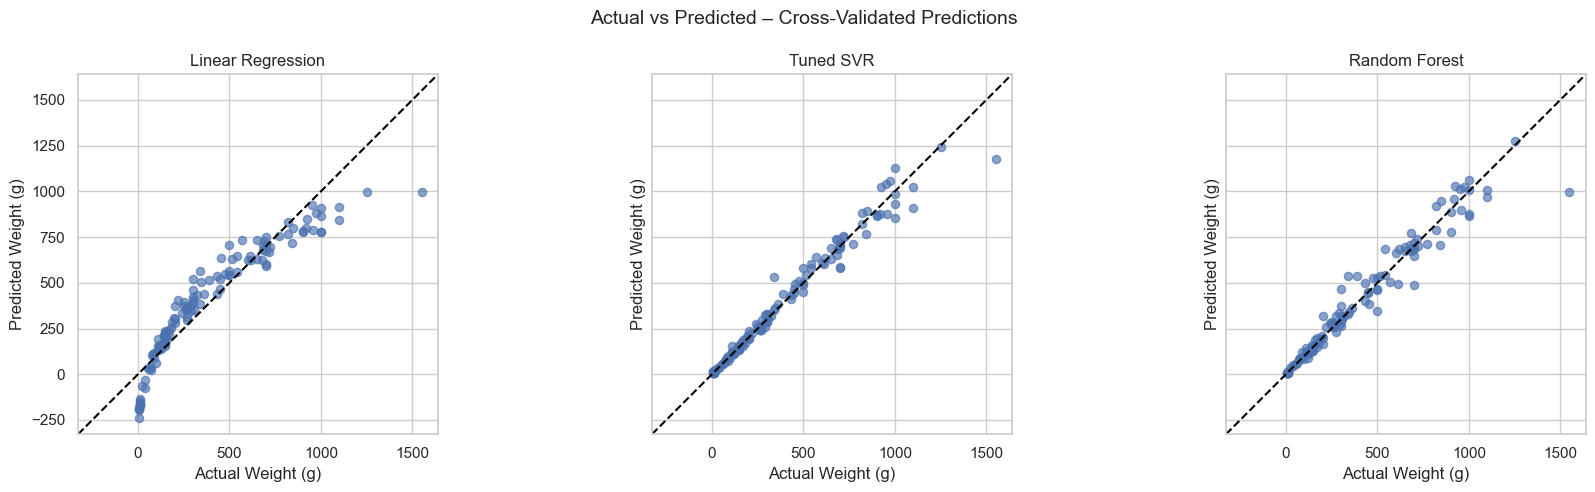

In [26]:

# Compare out-of-fold predictions on identical validation observations.

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5),
    sharex=True,
    sharey=True
)

# Use consistent axis limits across all models.
all_values = np.concatenate([
    y_train.to_numpy(),
    *oof_predictions.values()
])

lower = all_values.min()
upper = all_values.max()
padding = (upper - lower) * 0.05
limits = [lower - padding, upper + padding]

for ax, (model_name, y_pred) in zip(
    axes,
    oof_predictions.items()
):
    ax.scatter(
        y_train,
        y_pred,
        alpha=0.65,
        s=35
    )

    # Diagonal reference line: predicted = actual.
    ax.plot(
        limits,
        limits,
        color="black",
        linestyle="--",
        linewidth=1.5
    )

    ax.set_xlim(limits)
    ax.set_ylim(limits)
    ax.set_aspect("equal", adjustable="box")

    ax.set_title(model_name)
    ax.set_xlabel("Actual Weight (g)")
    ax.set_ylabel("Predicted Weight (g)")

plt.suptitle(
    "Actual vs Predicted – Cross-Validated Predictions",
    fontsize=14
)

plt.tight_layout()
plt.show()


## 3.8 Final Test Evaluation


### 3.8.1 Final Test Procedure

Following model development, cross-validation, and SVR hyperparameter optimization, the nine regression configurations are evaluated on the independent test dataset.

Each finalized model is fitted using all 126 training observations and used to predict the weights of the 32 held-out test observations.

The same test observations are used for every model combination to ensure comparability.

Model performance is assessed using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the Coefficient of Determination (R²), as defined in Section 3.5.1.

The SVR models use the hyperparameters selected through GridSearchCV on the training data. Linear Regression and Random Forest retain their previously specified configurations.

The test dataset has not been used for model development or hyperparameter selection. No further model adjustments will be made based on the final test results.


### 3.8.2 Test Permformance Results

In [27]:

from sklearn.base import clone
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Store the final fitted models, predictions, and evaluation results.
final_models = {}
test_predictions = {}
test_results = []

# Evaluate all nine predefined model combinations.
for group_name in feature_groups:

    X_train = X_train_groups[group_name]
    X_test = X_test_groups[group_name]

    for model_name, base_model in models.items():

        # Use the selected hyperparameters for SVR.
        # Other algorithms retain their original configurations.
        if model_name == "Support Vector Regression":
            model = clone(tuned_svr_models[group_name])
        else:
            model = clone(base_model)

        # Fit the finalized model on the complete training dataset.
        model.fit(X_train, y_train)

        # Predict previously unseen fish weights.
        y_pred = model.predict(X_test)

        # Save the fitted model and predictions for later analysis.
        model_key = (group_name, model_name)
        final_models[model_key] = model
        test_predictions[model_key] = y_pred

        # Calculate independent test performance metrics.
        test_results.append({
            "Feature Group": group_name,
            "Algorithm": model_name,
            "Test MAE (g)": mean_absolute_error(y_test, y_pred),
            "Test RMSE (g)": np.sqrt(
                mean_squared_error(y_test, y_pred)
            ),
            "Test R²": r2_score(y_test, y_pred)
        })

# Present the nine model combinations.
test_results_df = pd.DataFrame(test_results)

test_results_df = test_results_df.sort_values(
    by="Test MAE (g)",
    ascending=True
).reset_index(drop=True)

display(test_results_df.round(2))


,Feature Group,Algorithm,Test MAE (g),Test RMSE (g),Test R²
0,Group 3 - All features,Support Vector Regression,40.50,82.89,0.96
1,Group 2 - Body dimensions,Random Forest Regression,46.08,83.79,0.96
2,Group 2 - Body dimensions,Support Vector Regression,47.77,101.67,0.95
3,Group 3 - All features,Random Forest Regression,48.70,82.59,0.96
4,Group 1 - Length,Support Vector Regression,55.24,92.96,0.96
5,Group 1 - Length,Random Forest Regression,66.56,111.81,0.94
6,Group 3 - All features,Linear Regression,101.69,157.91,0.87
7,Group 1 - Length,Linear Regression,106.14,138.02,0.90
8,Group 2 - Body dimensions,Linear Regression,107.01,156.72,0.87



### 3.8.3 Comparison of Test Performance

The test results are visualized to compare predictive accuracy across the nine model configurations.

Mean Absolute Error (MAE) is used as the primary comparison metric because it expresses average prediction error directly in grams.

Lower values indicate more accurate predictions. The figure allows differences between algorithms and feature combinations to be examined visually.


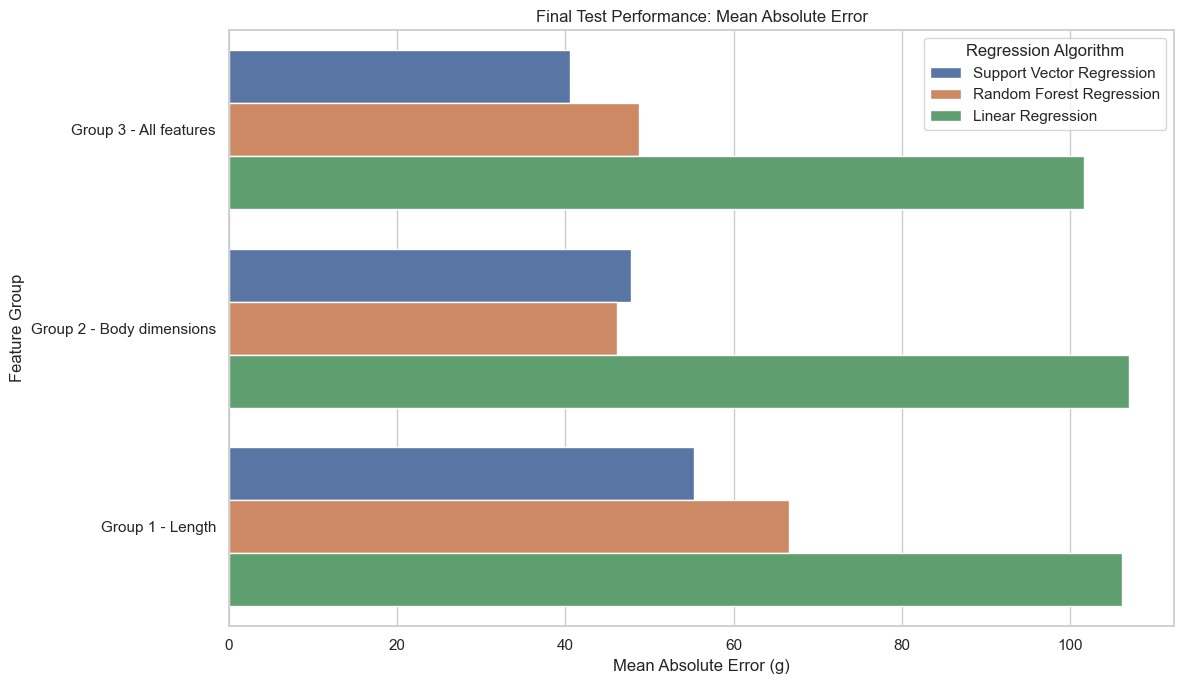

In [28]:

# Visualize the test MAE of all nine model combinations.

fig, ax = plt.subplots(figsize=(12, 7))

sns.barplot(
    data=test_results_df,
    x="Test MAE (g)",
    y="Feature Group",
    hue="Algorithm",
    ax=ax
)

ax.set(
    title="Final Test Performance: Mean Absolute Error",
    xlabel="Mean Absolute Error (g)",
    ylabel="Feature Group"
)

ax.legend(
    title="Regression Algorithm",
    loc="best"
)

plt.tight_layout()
plt.show()


### 3.8.4 Actual vs Predicted - Test Data

Actual-versus-predicted plots are used to visualize the predictive performance of three representative model configurations on the held-out test dataset.

The selected configurations are:

- Linear Regression – Feature Group 3
- Tuned Support Vector Regression – Feature Group 3
- Random Forest Regression – Feature Group 2

Each point represents a test observation, with actual fish weight on the horizontal axis and predicted fish weight on the vertical axis.

The dashed diagonal represents perfect agreement between actual and predicted weight. Deviations from this line indicate prediction errors.

Unlike the visualizations in Section 3.7, these predictions are generated using models fitted on the complete training dataset and evaluated on the independent test observations.

Identical axis limits are used across the plots to support visual comparison.


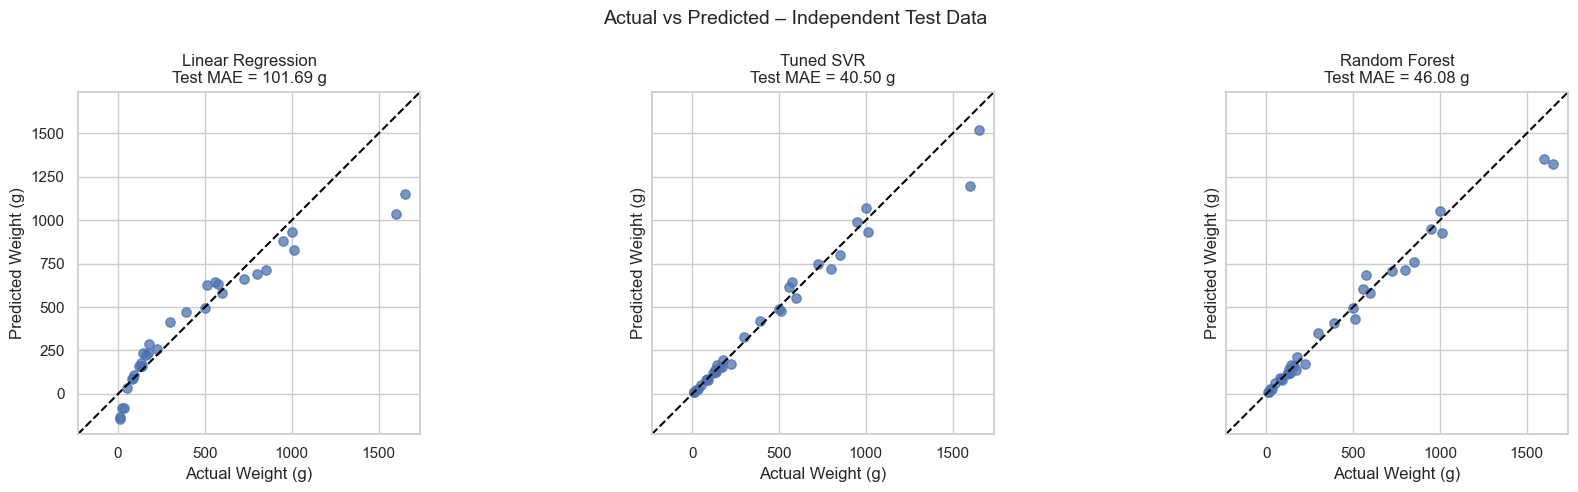

In [29]:

# Select three representative model configurations.
# These configurations were specified before final test evaluation.

selected_test_models = {
    "Linear Regression": (
        "Group 3 - All features",
        "Linear Regression"
    ),
    "Tuned SVR": (
        "Group 3 - All features",
        "Support Vector Regression"
    ),
    "Random Forest": (
        "Group 2 - Body dimensions",
        "Random Forest Regression"
    )
}

# Retrieve predictions for the selected configurations.
selected_test_predictions = {
    label: test_predictions[model_key]
    for label, model_key in selected_test_models.items()
}

# Use identical limits for all three plots.
all_values = np.concatenate([
    y_test.to_numpy(),
    *selected_test_predictions.values()
])

lower = all_values.min()
upper = all_values.max()
padding = 0.05 * (upper - lower)
limits = [lower - padding, upper + padding]

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5),
    sharex=True,
    sharey=True
)

for ax, (label, predictions) in zip(
    axes,
    selected_test_predictions.items()
):
    # Plot actual and predicted weights.
    ax.scatter(
        y_test,
        predictions,
        alpha=0.75,
        s=45
    )

    # Perfect prediction reference line.
    ax.plot(
        limits,
        limits,
        color="black",
        linestyle="--",
        linewidth=1.5
    )

    # Display the test MAE for each selected model.
    mae = mean_absolute_error(y_test, predictions)

    ax.set_title(f"{label}\nTest MAE = {mae:.2f} g")
    ax.set_xlabel("Actual Weight (g)")
    ax.set_ylabel("Predicted Weight (g)")

    ax.set_xlim(limits)
    ax.set_ylim(limits)
    ax.set_aspect("equal", adjustable="box")

plt.suptitle(
    "Actual vs Predicted – Independent Test Data",
    fontsize=14
)

plt.tight_layout()
plt.show()
